# HCI2000 Data Preprocessing and Analysis



# 0.0 Setup


## 0.1 Explanation of raw data

The study produces four raw files, described below in the order they are collected. Files 1, 3 and 4 are Google Forms exports, and file 2 is written by the Hammerspoon controller. All four share a **participant code** (`P###`), which is how they are linked. Row counts assume the planned sample of 16 participants.

### 1. `screening_survey.csv`

The screening form, answered **before** the session. **One row = one person who answered it**, including people who were later screened out. Its 11 columns hold the submission timestamp, consent, name, age, and answers about browser habits (laptop use, Chrome use, number of tabs, usual tab orientation). The last column is the participant code, which the researcher fills in after the session. It is blank for anyone who did not take part.

### 2. `main_data.csv`

Written by the controller during the retrieval trials. **One row = one trial.** Each session is saved in its own file (`records/main/<participant>/<session_id>/main_data.csv`) with 24 rows (4 condition blocks × 6 trials), so the 16 files stack into 384 rows.

Its 25 columns describe:
- **who and when**: session, participant and counterbalancing group
- **which condition and trial**: orientation, tab load, content set, target, and the target's tab position
- **how the trial ended** (`controller_status`)
- **the outcomes**: retrieval time, number of tabs opened, wrong selections, whether the first selection was correct, and flags for no selection or technical loss

`retrieval_time_s` is filled only for trials the controller completed automatically.

### 3. `block_survey.csv`

The NASA-TLX form, answered **after each condition block**. **One row = one participant's ratings for one condition**, so there are 4 rows per participant (64 in total). Its 10 columns hold the timestamp, participant code, the condition just finished (e.g. `H-L: Horizontal Low`), the six workload ratings on a 0–10 scale, and an optional comment.

### 4. `weighting_form.csv`

The NASA-TLX weighting form, answered **once, after all four blocks**. **One row = one participant** (16 in total). Its 17 columns hold the timestamp, participant code, and one column for each of the 15 pairs of workload dimensions. Each pair cell contains the dimension the participant chose as contributing more to their workload.

## 0.2 Importing Modules and Assigning File Paths

In [186]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

DATA_DIR = Path("dummy_data")            # later: folder with the real exports
RECORDS_DIR = DATA_DIR / "records" / "main"

SCREENING_FILE = DATA_DIR / "screening_survey.csv"
BLOCK_SURVEY_FILE = DATA_DIR / "block_survey.csv"
WEIGHTING_FILE = DATA_DIR / "weighting_form.csv"

# Check that everything is where we expect it
for f in [SCREENING_FILE, BLOCK_SURVEY_FILE, WEIGHTING_FILE]:
    print(f"{f.name:<22} found: {f.exists()}")

main_data_files = sorted(RECORDS_DIR.glob("*/*/main_data.csv"))
print(f"main_data.csv files found: {len(main_data_files)}")

screening_survey.csv   found: True
block_survey.csv       found: True
weighting_form.csv     found: True
main_data.csv files found: 16


## 1.0 Data Cleaning and Preprocessing

### 1.1 Cleaning the raw CSV files

#### 1.1.1 Cleaning `main_data.csv`

##### 1.1.1.1 Combining the `main_data.csv` files

Each session's `main_data.csv` is read and stacked into one table, `main_data`. All files have the same 25 columns, so they line up directly. The checks confirm the expected results: every participant has 24 trials, and no trial appears twice.

In [187]:
main_data = pd.concat(
    [pd.read_csv(f) for f in main_data_files],
    ignore_index=True,
)

print(f"Files combined: {len(main_data_files)}")
print(f"Rows: {len(main_data)}  Columns: {main_data.shape[1]}")
print(f"Participants: {main_data['participant'].nunique()}")
print("Rows per participant:", main_data.groupby("participant").size().unique())
print("Duplicate trials:", main_data.duplicated(["participant", "block", "trial"]).sum())

main_data.head()

Files combined: 16
Rows: 384  Columns: 25
Participants: 16
Rows per participant: [24]
Duplicate trials: 0


,session_id,mode,participant,group,block,condition,orientation,tab_load,content_set,trial,...,visible_tab_count,controller_status,measurement_source,retrieval_time_s,total_tab_switches,incorrect_selections,first_selection_correct,no_selection,technical_loss,notes
0,20261116T010120Z-316433980481813,main,P001,2,1,H-H,H,high,C,T1,...,16,completed_auto,controller_accessibility_and_poll,2.702158,1,0,True,False,False,NaN
1,20261116T010120Z-316433980481813,main,P001,2,1,H-H,H,high,C,T2,...,16,completed_auto,controller_accessibility_and_poll,4.873476,1,0,True,False,False,NaN
2,20261116T010120Z-316433980481813,main,P001,2,1,H-H,H,high,C,T3,...,16,completed_auto,controller_accessibility_and_poll,3.657422,2,1,False,False,False,NaN
3,20261116T010120Z-316433980481813,main,P001,2,1,H-H,H,high,C,T4,...,16,completed_auto,controller_accessibility_and_poll,3.304708,1,0,True,False,False,NaN
4,20261116T010120Z-316433980481813,main,P001,2,1,H-H,H,high,C,T5,...,16,completed_auto,controller_accessibility_and_poll,3.585104,1,0,True,False,False,NaN


##### 1.1.1.2 Fixing `main_data.csv` column types

Some columns load with the wrong type, because pandas cannot store true/false values and blanks together in an ordinary true/false column:

- `first_selection_correct`, `no_selection`, `technical_loss` and `is_repeat` are converted to pandas' **`boolean`** type, which allows `True`, `False` and `<NA>`.
- `total_tab_switches` and `incorrect_selections` are converted to **`Int64`**, a whole-number type that also allows `<NA>`. Without it, a single blank count would turn the whole column into decimals (1.0, 2.0).

Blanks are kept as missing (`<NA>`), not filled with `False`. A blank means the value doesn't apply: for example, `first_selection_correct` is blank when no tab was opened, and `no_selection` is blank for interrupted trials.



In [188]:
bool_cols = ["first_selection_correct", "no_selection", "technical_loss", "is_repeat"]
count_cols = ["total_tab_switches", "incorrect_selections"]

main_data[bool_cols] = main_data[bool_cols].astype("boolean")
main_data[count_cols] = main_data[count_cols].astype("Int64")

# Check the new types and how many values are missing
main_data[bool_cols + count_cols].agg(["dtype", lambda s: s.isna().sum()]).set_axis(["type", "missing"])

,first_selection_correct,no_selection,technical_loss,is_repeat,total_tab_switches,incorrect_selections
type,boolean,boolean,boolean,boolean,Int64,Int64
missing,2,3,0,0,0,0


##### 1.1.1.3 Choosing trials for each analysis

No rows are deleted. Instead, two columns mark which trials each analysis uses (following paper sections 4.6.1 and 4.7):

- `include_rt`: **retrieval time** uses completed trials only (`completed_auto`), the only trials with a recorded time.
- `include_accuracy`: **first-selection accuracy** uses every trial where a first selection was observed and no technical loss affected it, whatever the outcome: completed, timed out, completed manually or interrupted. A first selection made before a break still counts; only the measurements the problem affected are left out. Trials with no selection are reported separately.

Slow responses and ordinary errors are kept.

The table below gives the trial counts per condition that the paper reports alongside the results.

In [189]:
main_data["include_rt"] = main_data["controller_status"].eq("completed_auto")
main_data["include_accuracy"] = (
    main_data["first_selection_correct"].notna()
    & ~main_data["technical_loss"].fillna(False).astype(bool)
)

# How each trial ended, per condition
print(pd.crosstab(main_data["condition"], main_data["controller_status"], margins=True, margins_name="Total"))

# How many trials each analysis uses, per condition
main_data.groupby("condition")[["include_rt", "include_accuracy"]].sum()

controller_status  completed_auto  completed_manual  interrupted  timeout  \
condition                                                                   
H-H                            94                 0            0        2   
H-L                            95                 0            1        0   
V-H                            95                 0            1        0   
V-L                            95                 1            0        0   
Total                         379                 1            2        2   

controller_status  Total  
condition                 
H-H                   96  
H-L                   96  
V-H                   96  
V-L                   96  
Total                384  


,include_rt,include_accuracy
condition,,
H-H,94,95
H-L,95,95
V-H,95,95
V-L,95,95


##### 1.1.1.4 Tidying the columns

Four columns are removed because they repeat information that is already in the table:

- `target_title`: each target is already identified by `content_set` + `target_id`. These are combined into a short code, `target_code` (e.g. `A-P1`). The full titles are listed in `.hammerspoon/study/materials.lua`.
- `task_tab_count` and `visible_tab_count`: always 5/6 at low load and 15/16 at high load, so they repeat `tab_load`.
- `notes`: always left blank by the controller.

In [190]:
main_data["target_code"] = main_data["content_set"] + "-" + main_data["target_id"]

main_data = main_data.drop(columns=["target_title", "task_tab_count", "visible_tab_count", "notes"])

print(f"Columns: {main_data.shape[1]}")
print(f"Unique targets: {main_data['target_code'].nunique()}")
main_data.head()

Columns: 24
Unique targets: 20


,session_id,mode,participant,group,block,condition,orientation,tab_load,content_set,trial,...,measurement_source,retrieval_time_s,total_tab_switches,incorrect_selections,first_selection_correct,no_selection,technical_loss,include_rt,include_accuracy,target_code
0,20261116T010120Z-316433980481813,main,P001,2,1,H-H,H,high,C,T1,...,controller_accessibility_and_poll,2.702158,1,0,True,False,False,True,True,C-P3
1,20261116T010120Z-316433980481813,main,P001,2,1,H-H,H,high,C,T2,...,controller_accessibility_and_poll,4.873476,1,0,True,False,False,True,True,C-P4
2,20261116T010120Z-316433980481813,main,P001,2,1,H-H,H,high,C,T3,...,controller_accessibility_and_poll,3.657422,2,1,False,False,False,True,True,C-P5
3,20261116T010120Z-316433980481813,main,P001,2,1,H-H,H,high,C,T4,...,controller_accessibility_and_poll,3.304708,1,0,True,False,False,True,True,C-P1
4,20261116T010120Z-316433980481813,main,P001,2,1,H-H,H,high,C,T5,...,controller_accessibility_and_poll,3.585104,1,0,True,False,False,True,True,C-P3


##### 1.1.1.5 Checking `main_data` against the study design

Before `main_data` is used, it is checked against what the study design says it should contain. Every check should print `True`. A `False` means something went wrong in a session, such as a missing or repeated trial, or a session that was restarted, and must be investigated before continuing.

The checks cover:
- **Structure:** only main-study sessions; 24 trials per participant (4 conditions × 6 trials); one counterbalancing group per participant; no duplicate trials.
- **Labels:** `condition` agrees with `orientation` and `tab_load`.
- **Values:** retrieval time is present only for completed trials and lies between 0 and the 20-second limit; for completed trials, tab switches = wrong selections + 1.

In [191]:
completed = main_data[main_data["controller_status"] == "completed_auto"]
per_condition = main_data.groupby(["participant", "condition"]).size()

checks = {
    "Only main-study sessions": main_data["mode"].eq("main").all(),
    "24 trials per participant": main_data.groupby("participant").size().eq(24).all(),
    "4 conditions x 6 trials per participant": per_condition.eq(6).all()
        and per_condition.groupby("participant").size().eq(4).all(),
    "One group per participant": main_data.groupby("participant")["group"].nunique().eq(1).all(),
    "No duplicate trials": not main_data.duplicated(["participant", "block", "trial"]).any(),
    "Condition matches orientation and load": (
        main_data["condition"] == main_data["orientation"] + "-" + main_data["tab_load"].str[0].str.upper()
    ).all(),
    "Retrieval time only for completed trials": main_data["retrieval_time_s"].notna().eq(main_data["include_rt"]).all(),
    "Retrieval times between 0 and 20 s": completed["retrieval_time_s"].between(0, 20).all(),
    "Completed: tab switches = wrong selections + 1": (
        completed["total_tab_switches"] == completed["incorrect_selections"] + 1
    ).all(),
}

pd.Series(checks, name="passed").to_frame()

,passed
Only main-study sessions,True
24 trials per participant,True
4 conditions x 6 trials per participant,True
One group per participant,True
No duplicate trials,True
Condition matches orientation and load,True
Retrieval time only for completed trials,True
Retrieval times between 0 and 20 s,True
Completed: tab switches = wrong selections + 1,True


#### 1.1.2 Cleaning `block_survey.csv`

##### 1.1.2.1 Loading and renaming the columns

The Google Forms export uses the full question text as column names. These are replaced with short names. `participant` and `condition` are named the same as in `main_data`, because the two tables are joined on these columns later.

The new names are assigned by **position**, so the table printed first shows each original header next to its new name. Check that every row matches before continuing. If the form's questions are ever reordered, this is where it would show.

In [192]:
block_survey = pd.read_csv(BLOCK_SURVEY_FILE)

new_names = [
    "timestamp", "participant", "condition",
    "mental", "physical", "temporal", "performance", "effort", "frustration",
    "comment",
]

# Show original header -> new name, to confirm the order before renaming
print(pd.DataFrame({"original": [c[:50] for c in block_survey.columns], "new": new_names}))

block_survey.columns = new_names
block_survey.head()

                                            original          new
0                                          Timestamp    timestamp
1            Participant Code (Filled by researcher)  participant
2          What condition block did you just finish?    condition
3  Mental Demand: How much mental and perceptual ...       mental
4  Physical Demand: How much physical activity wa...     physical
5  Temporal Demand: How much time pressure did yo...     temporal
6  Performance: How successful do you think you w...  performance
7  Effort: How hard did you have to work (mentall...       effort
8  Frustration Level: How insecure, discouraged, ...  frustration
9  Optional: Any thoughts you would like to share...      comment


,timestamp,participant,condition,mental,physical,temporal,performance,effort,frustration,comment
0,11/16/2026 9:14:30,P001,H-H: Horizontal High,6,0,4,4,7,5,NaN
1,11/16/2026 9:19:28,P001,H-L: Horizontal Low,3,0,1,1,3,1,NaN
2,11/16/2026 9:25:06,P001,V-H: Vertical High,4,1,4,4,3,5,Vertical list helped with many tabs
3,11/16/2026 9:29:58,P001,V-L: Vertical Low,2,0,3,2,3,3,NaN
4,11/16/2026 11:02:27,P002,V-H: Vertical High,5,2,3,3,3,2,Vertical list helped with many tabs


##### 1.1.2.2 Fixing labels

Two columns are made consistent with `main_data` so the tables can be joined later:

- `condition`: the form's labels (e.g. `H-L: Horizontal Low`) are cut at the colon, leaving the short code (`H-L`) used in `main_data`.
- `participant`: the code is typed in by hand, so stray spaces are removed and letters are made uppercase (e.g. `" p001"` → `P001`). Without this, a code that looks right could fail to match.

In [193]:
print("Conditions before:", sorted(block_survey["condition"].unique()))

block_survey["condition"] = block_survey["condition"].str.split(":").str[0].str.strip()
block_survey["participant"] = block_survey["participant"].str.strip().str.upper()

print("Conditions after: ", sorted(block_survey["condition"].unique()))
print("Participants:", block_survey["participant"].nunique())

Conditions before: ['H-H: Horizontal High', 'H-L: Horizontal Low', 'V-H: Vertical High', 'V-L: Vertical Low']
Conditions after:  ['H-H', 'H-L', 'V-H', 'V-L']
Participants: 16


##### 1.1.2.3 Rescaling the ratings to 0–100

The form collects each of the six ratings on a 0–10 scale. The standard NASA-TLX scale is 0–100, so every rating is multiplied by 10 (e.g. 7 → 70).

The cell first checks that the ratings are still between 0 and 10. This stops the cell from rescaling twice if it is run again by accident. If it stops, re-run the notebook from 1.1.2.1.

In [194]:
tlx_cols = ["mental", "physical", "temporal", "performance", "effort", "frustration"]

# Guard: only rescale ratings that are still on the 0-10 scale
if not block_survey[tlx_cols].stack().between(0, 10).all():
    raise ValueError("Ratings are not on the 0-10 scale. Already rescaled? Re-run from 1.1.2.1.")

block_survey[tlx_cols] = block_survey[tlx_cols] * 10

block_survey[tlx_cols].agg(["min", "max"])

,mental,physical,temporal,performance,effort,frustration
min,10,0,0,0,0,0
max,90,50,80,70,90,70


##### 1.1.2.4 Checking `block_survey` against the study design

Every check should print `True`:

- **Structure:** each participant has 4 rows, and no condition appears twice for the same participant (e.g. a form submitted twice).
- **Values:** all six ratings are filled in and lie between 0 and 100.
- **Links to `main_data`:** the same participants appear in both tables, and every participant × condition pair in the survey matches one in `main_data`. This is what the later join relies on.

If the last check fails, the cell also lists the pairs that don't match, which usually points to a mistyped participant code or a wrong condition selected on the form.

In [195]:
survey_pairs = set(zip(block_survey["participant"], block_survey["condition"]))
trial_pairs = set(zip(main_data["participant"], main_data["condition"]))

checks = {
    "4 rows per participant": block_survey.groupby("participant").size().eq(4).all(),
    "Each condition once per participant": not block_survey.duplicated(["participant", "condition"]).any(),
    "All six ratings filled in": block_survey[tlx_cols].notna().all().all(),
    "Ratings between 0 and 100": block_survey[tlx_cols].stack().between(0, 100).all(),
    "Same participants as main_data": set(block_survey["participant"]) == set(main_data["participant"]),
    "Every participant x condition matches main_data": survey_pairs == trial_pairs,
}

# If anything doesn't match, show exactly which pairs
if survey_pairs != trial_pairs:
    print("In survey but not in main_data:", sorted(survey_pairs - trial_pairs))
    print("In main_data but not in survey:", sorted(trial_pairs - survey_pairs))

pd.Series(checks, name="passed").to_frame()

,passed
4 rows per participant,True
Each condition once per participant,True
All six ratings filled in,True
Ratings between 0 and 100,True
Same participants as main_data,True
Every participant x condition matches main_data,True


#### 1.1.3 Cleaning `weighting_form.csv`

##### 1.1.3.1 Loading and renaming the columns

All column names are made short and lowercase to match the other tables: `Timestamp` → `timestamp`, the participant code column → `participant`, and each pair column to `<dimension>_vs_<dimension>` (e.g. `Mental Demand vs. Physical Demand` → `mental_vs_physical`).

`dimensions` maps each dimension's full name to its short name. The short names are the same as the rating columns in `block_survey`. This mapping is also used to convert the answers in 1.1.3.2.

In [196]:
dimensions = {
    "Mental Demand": "mental",
    "Physical Demand": "physical",
    "Temporal Demand": "temporal",
    "Performance": "performance",
    "Effort": "effort",
    "Frustration": "frustration",
}

def short_pair(header):
    """'Mental Demand vs. Physical Demand' -> 'mental_vs_physical'"""
    first, second = header.strip().split(" vs. ")
    return f"{dimensions[first]}_vs_{dimensions[second]}"

weighting = pd.read_csv(WEIGHTING_FILE)
weighting = weighting.rename(columns={
    "Timestamp": "timestamp",
    "Participant Code (Filled by Researcher)": "participant",
})
weighting = weighting.rename(columns={c: short_pair(c) for c in weighting.columns if " vs. " in c})

pair_cols = [c for c in weighting.columns if "_vs_" in c]
print(f"Pair columns found: {len(pair_cols)}")
weighting.head()

Pair columns found: 15


,timestamp,participant,mental_vs_physical,mental_vs_temporal,mental_vs_performance,mental_vs_effort,mental_vs_frustration,physical_vs_temporal,physical_vs_performance,physical_vs_effort,physical_vs_frustration,temporal_vs_performance,temporal_vs_effort,temporal_vs_frustration,performance_vs_frustration,performance_vs_effort,frustration_vs_effort
0,11/16/2026 9:33:51,P001,Mental Demand,Temporal Demand,Mental Demand,Effort,Mental Demand,Temporal Demand,Performance,Physical Demand,Frustration,Performance,Temporal Demand,Frustration,Performance,Performance,Frustration
1,11/16/2026 11:21:04,P002,Mental Demand,Mental Demand,Mental Demand,Effort,Mental Demand,Temporal Demand,Performance,Effort,Frustration,Performance,Effort,Frustration,Performance,Effort,Frustration
2,11/16/2026 14:05:31,P003,Mental Demand,Temporal Demand,Performance,Mental Demand,Mental Demand,Temporal Demand,Performance,Effort,Frustration,Performance,Effort,Frustration,Frustration,Effort,Effort
3,11/16/2026 15:49:44,P004,Mental Demand,Mental Demand,Mental Demand,Mental Demand,Frustration,Physical Demand,Performance,Effort,Frustration,Performance,Effort,Frustration,Performance,Performance,Frustration
4,11/17/2026 9:45:21,P005,Mental Demand,Mental Demand,Mental Demand,Mental Demand,Mental Demand,Temporal Demand,Performance,Physical Demand,Physical Demand,Performance,Effort,Temporal Demand,Frustration,Effort,Effort


##### 1.1.3.2 Fixing labels and checking the answers

- `participant`: tidied the same way as in 1.1.2.2 (spaces removed, letters uppercase).
- **Pair answers:** converted to the short names (e.g. `Mental Demand` → `mental`). Each answer must then be **one of the two dimensions in its column name**. In `mental_vs_physical`, the answer can only be `mental` or `physical`. An answer that isn't in `dimensions` (e.g. a typo or a renamed option in the form) turns blank and is counted as invalid.

The cell prints how many answers are invalid, which should be 0, and lists the rows with a problem, if any.

In [197]:
weighting["participant"] = weighting["participant"].str.strip().str.upper()
weighting[pair_cols] = weighting[pair_cols].apply(lambda col: col.str.strip().map(dimensions))

# True where the answer is one of the two dimensions in that column's name
valid = pd.DataFrame({col: weighting[col].isin(col.split("_vs_")) for col in pair_cols})

print(f"Invalid answers: {(~valid).sum().sum()}")
weighting.loc[~valid.all(axis=1), ["participant"] + pair_cols]   # rows with a problem (empty if none)

Invalid answers: 0


,participant,mental_vs_physical,mental_vs_temporal,mental_vs_performance,mental_vs_effort,mental_vs_frustration,physical_vs_temporal,physical_vs_performance,physical_vs_effort,physical_vs_frustration,temporal_vs_performance,temporal_vs_effort,temporal_vs_frustration,performance_vs_frustration,performance_vs_effort,frustration_vs_effort


##### 1.1.3.3 Counting the weights

A dimension's **weight** is the number of pairs in which the participant chose it. Each dimension appears in 5 of the 15 pairs, so its weight is between 0 (never chosen) and 5 (chosen every time).

The result is a new table, `weights`, with one row per participant and one column per dimension, named `<dimension>_weight` (e.g. `mental_weight`) so each weight is easy to match to its rating in `block_survey`.

In [198]:
weights = weighting[["participant"]].copy()
for name in dimensions.values():
    # count how many of the 15 answers equal this dimension
    weights[f"{name}_weight"] = (weighting[pair_cols] == name).sum(axis=1)

weights.head()

,participant,mental_weight,physical_weight,temporal_weight,performance_weight,effort_weight,frustration_weight
0,P001,3,1,3,4,1,3
1,P002,4,0,1,3,4,3
2,P003,3,0,2,3,4,3
3,P004,4,1,0,4,2,4
4,P005,5,2,2,2,3,1


##### 1.1.3.4 Checking `weights`

Every check should print `True`:

- **One row per participant:** the form was not submitted twice for the same code.
- **All 15 answers valid:** confirms the result of 1.1.3.2.
- **Weights between 0 and 5, adding up to 15:** each dimension appears in exactly 5 pairs, and every pair gives one point.
- **Same participants as `main_data`:** every participant who did the trials has a weighting form, and there are no extra codes.

If the last check fails, the cell lists which codes are missing or extra. A participant without a weighting form cannot get a weighted NASA-TLX score.

In [199]:
weight_cols = [f"{name}_weight" for name in dimensions.values()]

checks = {
    "One row per participant": not weights["participant"].duplicated().any(),
    "All 15 answers valid": valid.all().all(),
    "Weights between 0 and 5": weights[weight_cols].stack().between(0, 5).all(),
    "Weights add up to 15": weights[weight_cols].sum(axis=1).eq(15).all(),
    "Same participants as main_data": set(weights["participant"]) == set(main_data["participant"]),
}

missing = set(main_data["participant"]) - set(weights["participant"])
extra = set(weights["participant"]) - set(main_data["participant"])
if missing or extra:
    print("No weighting form:", sorted(missing))
    print("Not in main_data:", sorted(extra))

pd.Series(checks, name="passed").to_frame()

,passed
One row per participant,True
All 15 answers valid,True
Weights between 0 and 5,True
Weights add up to 15,True
Same participants as main_data,True


#### 1.1.4 Cleaning `screening_survey.csv`

##### 1.1.4.1 Loading and renaming the columns

As in 1.1.2.1, the full question headers are replaced by short names assigned by **position**. The printed table shows each original header next to its new name, so check that every row matches before continuing.

In [200]:
screening = pd.read_csv(SCREENING_FILE)

new_names = [
    "timestamp", "consent", "name", "age",
    "uses_laptop_browser", "browse_frequency", "uses_chrome",
    "multitab_frequency", "window_habit", "usual_orientation",
    "participant",
]

# Show original header -> new name, to confirm the order before renaming
print(pd.DataFrame({"original": [c[:50] for c in screening.columns], "new": new_names}))

screening.columns = new_names
screening.head()

                                             original                  new
0                                           Timestamp            timestamp
1                                     Do you consent?              consent
2        Last name, First name (e.g. Dela Cruz, Juan)                 name
3                                                 Age                  age
4   Do you regularly use a desktop or laptop brows...  uses_laptop_browser
5   How often do you use a desktop or laptop compu...     browse_frequency
6   Do you use Google Chrome as your main web brow...          uses_chrome
7   How often do you have multiple tabs open at th...   multitab_frequency
8   Do you usually keep your open tabs in a single...         window_habit
9        Which tab orientation do you typically use?     usual_orientation
10            Participant Code (Filled by Researcher)          participant


,timestamp,consent,name,age,uses_laptop_browser,browse_frequency,uses_chrome,multitab_frequency,window_habit,usual_orientation,participant
0,11/12/2026 9:22:21,I agree,"Ocampo, Rica",24,No,Rarely,Yes,Almost always,Usually in a single window,Horizontal (tabs along the top),NaN
1,11/12/2026 9:39:11,I do not agree,"Tan, Sam",23,Yes,A few times a week,No,Sometimes,Usually in a single window,Horizontal (tabs along the top),NaN
2,11/12/2026 12:24:29,I agree,"Garcia, Danica",23,Yes,Daily,No,Sometimes,Usually in a single window,Vertical (tabs along the side),P005
3,11/12/2026 23:10:26,I agree,"Bautista, Carlo",22,Yes,Daily,No,Almost always,Usually in a single window,Horizontal (tabs along the top),P004
4,11/13/2026 2:07:15,I agree,"Reyes, Miguel",19,Yes,A few times a week,No,Sometimes,Usually in a single window,Horizontal (tabs along the top),P002


##### 1.1.4.2 Checking eligibility

Everyone who signs up answers this form, so it also contains people who were **screened out** before a session. Each response is checked against the eligibility criteria in paper section 4.3:

- consented to take part
- aged 18 or over
- regularly uses a desktop or laptop browser
- has experience with multiple open tabs (any answer other than "Never")
- usually keeps tabs in a single browser window

The result is stored in a new `eligible` column. The table lists every response that did not meet a criterion and which one it failed. These people should have no participant code. The participant code is tidied first, as in 1.1.2.2.

In [201]:
screening["participant"] = screening["participant"].str.strip().str.upper()

criteria = pd.DataFrame({
    "consented": screening["consent"].eq("I agree"),
    "aged_18_plus": screening["age"].ge(18),
    "uses_laptop_browser": screening["uses_laptop_browser"].eq("Yes"),
    "uses_multiple_tabs": screening["multitab_frequency"].notna() & screening["multitab_frequency"].ne("Never"),
    "single_window": screening["window_habit"].eq("Usually in a single window"),
})
screening["eligible"] = criteria.all(axis=1)

print(f"Responses: {len(screening)}   Eligible: {screening['eligible'].sum()}   Not eligible: {(~screening['eligible']).sum()}")

# Which criterion each ineligible response failed (names are not shown)
failed = criteria.apply(lambda row: ", ".join(name for name, ok in row.items() if not ok), axis=1)
screening.loc[~screening["eligible"], ["timestamp", "participant"]].assign(failed=failed)

Responses: 18   Eligible: 11   Not eligible: 7


,timestamp,participant,failed
0,11/12/2026 9:22:21,NaN,uses_laptop_browser
1,11/12/2026 9:39:11,NaN,consented
6,11/13/2026 10:48:25,P007,single_window
7,11/13/2026 21:40:24,P009,single_window
10,11/14/2026 1:24:20,P010,single_window
14,11/15/2026 16:56:16,P012,single_window
17,11/16/2026 5:46:36,P015,single_window


##### 1.1.4.3 Keeping enrolled participants and removing names

The researcher adds a participant code only for people who completed a session, so **rows without a code are removed**. The `name` column is then removed: names were only needed to match people to their codes, and they should not appear in the analysis files.

In [202]:
enrolled = screening["participant"].notna()
print(f"Enrolled: {enrolled.sum()}   Not enrolled: {(~enrolled).sum()}")

screening = screening[enrolled].drop(columns="name").reset_index(drop=True)
screening.head()

Enrolled: 16   Not enrolled: 2


,timestamp,consent,age,uses_laptop_browser,browse_frequency,uses_chrome,multitab_frequency,window_habit,usual_orientation,participant,eligible
0,11/12/2026 12:24:29,I agree,23,Yes,Daily,No,Sometimes,Usually in a single window,Vertical (tabs along the side),P005,True
1,11/12/2026 23:10:26,I agree,22,Yes,Daily,No,Almost always,Usually in a single window,Horizontal (tabs along the top),P004,True
2,11/13/2026 2:07:15,I agree,19,Yes,A few times a week,No,Sometimes,Usually in a single window,Horizontal (tabs along the top),P002,True
3,11/13/2026 7:23:38,I agree,23,Yes,A few times a week,Yes,Sometimes,Usually in a single window,Vertical (tabs along the side),P003,True
4,11/13/2026 10:48:25,I agree,23,Yes,Daily,No,Often,Usually across several windows,Horizontal (tabs along the top),P007,False


##### 1.1.4.4 Checking `screening` against the study design

Every check should print `True`:

- **One row per participant**, and the **same participants as `main_data`**.
- **Every enrolled participant is eligible.** If not, the cell lists who. With real data, that means someone was enrolled who did not meet the criteria in 1.1.4.2, which must be resolved before analysis.

In [203]:
checks = {
    "One row per participant": not screening["participant"].duplicated().any(),
    "Same participants as main_data": set(screening["participant"]) == set(main_data["participant"]),
    "Every enrolled participant is eligible": screening["eligible"].all(),
}

if not screening["eligible"].all():
    print("Enrolled but not eligible:", sorted(screening.loc[~screening["eligible"], "participant"]))

pd.Series(checks, name="passed").to_frame()

Enrolled but not eligible: ['P007', 'P009', 'P010', 'P012', 'P015']


,passed
One row per participant,True
Same participants as main_data,True
Every enrolled participant is eligible,False


### 1.2 Merging

The cleaned tables are at three levels: `main_data` has one row per **trial**, `block_survey` one row per **participant × condition**, and `weights` one row per **participant**. The analysis (paper section 4.7) needs two tables:

- **Trial level:** `main_data`, as it is. First-selection accuracy is modelled trial by trial.
- **Condition level:** one row per participant × condition (16 × 4 = 64 rows), holding each participant's mean retrieval time, accuracy and weighted NASA-TLX for that condition. This table is built here as `condition_data`.

Tables are always joined on `participant` (and `condition`), never by row order. Each join uses pandas' `validate` option, which stops with an error if the keys don't match up as expected (e.g. a participant appearing twice).

#### 1.2.1 Calculating the NASA-TLX scores

Each participant's weights (from `weights`) are joined to each of their four rows in `block_survey`. Two scores are then calculated for every participant × condition:

- **Raw TLX:** the average of the six ratings.
- **Weighted TLX:** each rating multiplied by its weight, added up, and divided by 15 (the total of the weights). The result stays on the 0–100 scale.

The join keeps every survey row (`how="left"`). If a participant has no weighting form, their weighted TLX is left blank rather than guessed.

In [204]:
tlx = block_survey.merge(weights, on="participant", how="left", validate="many_to_one")

tlx["raw_tlx"] = tlx[tlx_cols].mean(axis=1)

weighted_sum = sum(tlx[name] * tlx[f"{name}_weight"] for name in tlx_cols)
tlx["weighted_tlx"] = weighted_sum / 15

tlx[["participant", "condition", "raw_tlx", "weighted_tlx"]].head()

,participant,condition,raw_tlx,weighted_tlx
0,P001,H-H,43.333333,45.333333
1,P001,H-L,15.000000,14.666667
2,P001,V-H,35.000000,39.333333
3,P001,V-L,21.666667,23.333333
4,P002,V-H,30.000000,33.333333


#### 1.2.2 Summarising the trials per participant × condition

The 24 trials of each participant are reduced to one row per condition (6 trials each):

- `mean_rt_s`: mean retrieval time, using only the trials marked `include_rt` (completed trials).
- `accuracy_pct`: percentage of correct first selections, using only the trials marked `include_accuracy`.
- **Counts** reported alongside them, as required by paper section 4.7.2: completed trials (`n_completed`), timeouts (`n_timeout`), trials with no selection (`n_no_selection`) and trials used for accuracy (`n_accuracy`).

In [205]:
keys = ["participant", "condition"]

trial_summary = main_data.groupby(keys).agg(
    group=("group", "first"),
    orientation=("orientation", "first"),
    tab_load=("tab_load", "first"),
    n_trials=("trial", "size"),
    n_completed=("include_rt", "sum"),
    n_timeout=("controller_status", lambda s: (s == "timeout").sum()),
    n_no_selection=("no_selection", "sum"),
    n_accuracy=("include_accuracy", "sum"),
)

rt_trials = main_data[main_data["include_rt"]]
acc_trials = main_data[main_data["include_accuracy"]]

trial_summary["mean_rt_s"] = rt_trials.groupby(keys)["retrieval_time_s"].mean()
trial_summary["accuracy_pct"] = acc_trials.groupby(keys)["first_selection_correct"].mean() * 100

trial_summary = trial_summary.reset_index()
trial_summary.head()

,participant,condition,group,orientation,tab_load,n_trials,n_completed,n_timeout,n_no_selection,n_accuracy,mean_rt_s,accuracy_pct
0,P001,H-H,2,H,high,6,6,0,0,6,3.608509,83.333333
1,P001,H-L,2,H,low,6,6,0,0,6,2.125981,100.0
2,P001,V-H,2,V,high,6,6,0,0,6,2.752539,100.0
3,P001,V-L,2,V,low,6,6,0,0,6,2.190790,100.0
4,P002,H-H,4,H,high,6,5,1,0,6,3.518501,50.0


#### 1.2.3 Joining into `condition_data`

The trial summary and the TLX scores are joined on participant + condition. Both have exactly one row per participant × condition, so the join is one-to-one (`validate="one_to_one"`). Only the TLX columns needed for the analysis are kept; the individual ratings and weights stay in `tlx`.

In [206]:
condition_data = trial_summary.merge(
    tlx[keys + ["raw_tlx", "weighted_tlx"]],
    on=keys,
    how="left",
    validate="one_to_one",
)

print(f"Rows: {len(condition_data)}   Columns: {condition_data.shape[1]}")
condition_data.head()

Rows: 64   Columns: 14


,participant,condition,group,orientation,tab_load,n_trials,n_completed,n_timeout,n_no_selection,n_accuracy,mean_rt_s,accuracy_pct,raw_tlx,weighted_tlx
0,P001,H-H,2,H,high,6,6,0,0,6,3.608509,83.333333,43.333333,45.333333
1,P001,H-L,2,H,low,6,6,0,0,6,2.125981,100.0,15.000000,14.666667
2,P001,V-H,2,V,high,6,6,0,0,6,2.752539,100.0,35.000000,39.333333
3,P001,V-L,2,V,low,6,6,0,0,6,2.190790,100.0,21.666667,23.333333
4,P002,H-H,4,H,high,6,5,1,0,6,3.518501,50.0,40.000000,46.000000


#### 1.2.4 Checking `condition_data`

Every check should print `True`:

- **Structure:** 64 rows (16 participants × 4 conditions), each pair once, and 6 trials behind every row.
- **Nothing lost in the joins:** every row has a TLX score, and the trial counts add up to the 384 trials in `main_data`.
- **Values:** both TLX scores lie between 0 and 100, and accuracy between 0 and 100 %.

If a check fails, the most likely cause is a participant or condition label that didn't match in an earlier step (see the checks in 1.1.2.4 and 1.1.3.4).

In [207]:
n_participants = main_data["participant"].nunique()

checks = {
    "One row per participant x condition": len(condition_data) == n_participants * 4
        and not condition_data.duplicated(keys).any(),
    "6 trials behind every row": condition_data["n_trials"].eq(6).all(),
    "Trial counts add up to main_data": condition_data["n_trials"].sum() == len(main_data),
    "Every row has a raw TLX score": condition_data["raw_tlx"].notna().all(),
    "Every row has a weighted TLX score": condition_data["weighted_tlx"].notna().all(),
    "TLX scores between 0 and 100": condition_data[["raw_tlx", "weighted_tlx"]].stack().between(0, 100).all(),
    "Accuracy between 0 and 100 %": condition_data["accuracy_pct"].dropna().between(0, 100).all(),
}

pd.Series(checks, name="passed").to_frame()

,passed
One row per participant x condition,True
6 trials behind every row,True
Trial counts add up to main_data,True
Every row has a raw TLX score,True
Every row has a weighted TLX score,True
TLX scores between 0 and 100,True
Accuracy between 0 and 100 %,True


### 1.3 Saving the cleaned tables

The finished tables are saved as CSV files in a `cleaned/` folder inside `DATA_DIR`, so the dummy-data results stay separate from the real ones. Section 2.0, or another tool such as R, can then start from these files without re-running the cleaning.

| File | Table | One row = | Used for |
|---|---|---|---|
| `trial_level.csv` | `main_data` | one trial | First-selection accuracy (trial-level model), trial counts |
| `condition_level.csv` | `condition_data` | one participant × condition | Retrieval time and weighted NASA-TLX, descriptive tables |
| `participants.csv` | `screening` | one participant | Describing the sample |

Each file is read back after saving to confirm it has the same number of rows and columns. Blank values (`<NA>`) are saved as empty cells.

In [208]:
CLEANED_DIR = DATA_DIR / "cleaned"
CLEANED_DIR.mkdir(exist_ok=True)

outputs = {
    "trial_level.csv": main_data,
    "condition_level.csv": condition_data,
    "participants.csv": screening,
}

for filename, table in outputs.items():
    path = CLEANED_DIR / filename
    table.to_csv(path, index=False)
    saved = pd.read_csv(path)
    status = "OK" if saved.shape == table.shape else "MISMATCH"
    print(f"{status:<8} {filename:<22} {saved.shape[0]:>4} rows  {saved.shape[1]:>3} columns")

OK       trial_level.csv         384 rows   24 columns
OK       condition_level.csv      64 rows   14 columns
OK       participants.csv         16 rows   11 columns


# 2.0 Data Analysis

## 2.1 Descriptive statistics



Following paper sections 4.7.1 and 4.7.2, the results are first described before any test is run: 
- who took part, 
- the average of each outcome per condition, 
- and how many trials each average is based on.

Conditions are always listed in the order `H-L`, `H-H`, `V-L`, `V-H` (horizontal first, then vertical; low load before high load).

### 2.1.1 Describing the participants

- Age (mean, SD and range)
- background answers from the screening survey: 
    - main browser, 
    - usual tab orientation, 
    - how often participants have multiple tabs open, and 
    - how often they browse on a desktop or laptop. 
    
These give context for interpreting the results, e.g. how many participants were already used to vertical tabs.

In [209]:
CONDITION_ORDER = ["H-L", "H-H", "V-L", "V-H"]

age = screening["age"]
print(f"Participants: {len(screening)}")
print(f"Age: mean {age.mean():.1f}, SD {age.std():.1f}, range {age.min()}-{age.max()}")

background = {
    "Uses Chrome as main browser": "uses_chrome",
    "Usual tab orientation": "usual_orientation",
    "Has multiple tabs open": "multitab_frequency",
    "Browses on a desktop/laptop": "browse_frequency",
}
for label, col in background.items():
    print(f"\n{label}:")
    print(screening[col].value_counts().to_string())

Participants: 16
Age: mean 21.2, SD 1.8, range 19-24

Uses Chrome as main browser:
uses_chrome
No     8
Yes    8

Usual tab orientation:
usual_orientation
Horizontal (tabs along the top)    11
Vertical (tabs along the side)      5

Has multiple tabs open:
multitab_frequency
Sometimes        10
Often             5
Almost always     1

Browses on a desktop/laptop:
browse_frequency
Daily                 10
A few times a week     6


### 2.1.2 Outcomes per condition

For each condition: the **mean** and **SD** of the three main outcomes, and the **count** of participants each is based on. Each participant contributes one value per condition (from `condition_data`), so the mean is the average of the 16 participants' values.

- `mean_rt_s`: retrieval time in seconds (completed trials only)
- `accuracy_pct`: first-selection accuracy in %
- `weighted_tlx`: weighted NASA-TLX, 0–100

In [210]:
outcomes = ["mean_rt_s", "accuracy_pct", "weighted_tlx"]

summary = (
    condition_data.groupby("condition")[outcomes]
    .agg(["mean", "std", "count"])
    .reindex(CONDITION_ORDER)
    .round(2)
)
summary

mean_rt_s             accuracy_pct              weighted_tlx        \
               mean   std count         mean    std count         mean   std   
condition                                                                      
H-L            2.16  0.27    16        95.83   9.62    16        24.92  8.50   
H-H            3.33  0.34    16        70.42  15.72    16        54.96  8.32   
V-L            2.17  0.36    16        94.79   7.98    16        28.25  9.18   
V-H            2.73  0.34    16        90.62  14.87    16        39.50  8.58   

                 
          count  
condition        
H-L          16  
H-H          16  
V-L          16  
V-H          16

The same condition means as a plot. Each panel shows one outcome, with tab load on the x-axis and one line per orientation. Error bars show ±1 standard error (SE) across the 16 participants.

How to read it:
- **RQ1 (orientation):** does one line sit higher than the other overall?
- **RQ2 (tab load):** do the lines rise or fall from low to high load?
- **RQ3 (interaction):** are the lines **not parallel**? A gap that widens at high load means the orientation difference depends on tab load, the pattern the primary hypothesis predicts.

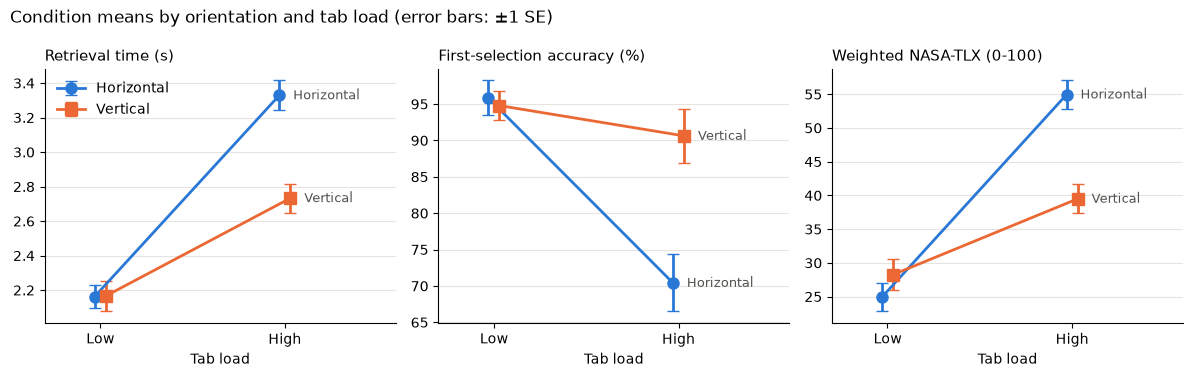

In [211]:
ORIENTATION_STYLE = {
    "H": {"label": "Horizontal", "color": "#2a78d6", "marker": "o", "offset": -0.03},
    "V": {"label": "Vertical",   "color": "#eb6834", "marker": "s", "offset": 0.03},
}
PANELS = {
    "mean_rt_s": "Retrieval time (s)",
    "accuracy_pct": "First-selection accuracy (%)",
    "weighted_tlx": "Weighted NASA-TLX (0-100)",
}

# Mean and standard error of the participants' values per orientation x load
means = condition_data.groupby(["orientation", "tab_load"])[list(PANELS)].agg(["mean", "sem"])

fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
for ax, (col, title) in zip(axes, PANELS.items()):
    for orientation, style in ORIENTATION_STYLE.items():
        m = means.loc[orientation].reindex(["low", "high"])
        x = np.array([0, 1]) + style["offset"]   # small shift so the error bars don't overlap
        ax.errorbar(x, m[(col, "mean")], yerr=m[(col, "sem")],
                    color=style["color"], marker=style["marker"], markersize=8,
                    linewidth=2, capsize=4, label=style["label"])
        # Label each line at its right end
        ax.annotate(style["label"], (x[-1], m[(col, "mean")].iloc[-1]), xytext=(10, 0),
                    textcoords="offset points", va="center", fontsize=9, color="#52514e")
    ax.set_title(title, fontsize=11, loc="left")
    ax.set_xticks([0, 1], ["Low", "High"])
    ax.set_xlabel("Tab load")
    ax.set_xlim(-0.3, 1.6)
    ax.grid(axis="y", color="#e5e4e0", linewidth=0.8)
    ax.spines[["top", "right"]].set_visible(False)

axes[0].legend(frameon=False, loc="upper left")
fig.suptitle("Condition means by orientation and tab load (error bars: ±1 SE)", x=0.01, ha="left", fontsize=12)
fig.tight_layout()
plt.show()

### 2.1.3 Averaged comparisons for RQ1 and RQ2

Paper section 4.7.2 asks for summaries of:

- **RQ1 (orientation):** horizontal vs vertical, each **averaged over both tab loads**
- **RQ2 (tab load):** low vs high, each **averaged over both orientations**

Each participant's two values are averaged first, e.g. their H-L and H-H retrieval times give one "horizontal" value. The mean and SD are then taken across participants. Averaging within each participant first keeps the comparison within-person, which matches how the repeated-measures analysis in 2.3 treats the data.

In [212]:
def averaged_over(factor, order):
    """Mean and SD per level of `factor`, after averaging each participant's two conditions."""
    per_participant = condition_data.groupby(["participant", factor])[outcomes].mean()
    return per_participant.groupby(factor).agg(["mean", "std"]).reindex(order).round(2)

print("RQ1 - Orientation (averaged over tab load)")
display(averaged_over("orientation", ["H", "V"]))

print("RQ2 - Tab load (averaged over orientation)")
display(averaged_over("tab_load", ["low", "high"]))

RQ1 - Orientation (averaged over tab load)


mean_rt_s       accuracy_pct       weighted_tlx      
                 mean   std         mean   std         mean   std
orientation                                                      
H                2.75  0.25        83.12  8.09        39.94  7.60
V                2.45  0.30        92.71  7.38        33.88  8.38

RQ2 - Tab load (averaged over orientation)


mean_rt_s       accuracy_pct       weighted_tlx      
              mean   std         mean   std         mean   std
tab_load                                                      
low           2.16  0.25        95.31  6.78        26.58  8.23
high          3.03  0.27        80.52  9.94        47.23  7.42

### 2.1.4 Trial counts per condition

The number of trials behind each average, as paper section 4.7.2 requires: averages based only on completed trials can hide difficulties in a condition with more timeouts.

- `n_trials`: all trials (16 participants × 6)
- `n_completed`: completed trials, used for retrieval time
- `n_timeout`: trials that reached the 20-second limit
- `n_no_selection`: timed-out trials in which no tab was opened
- `n_accuracy`: trials used for first-selection accuracy

In [213]:
trial_counts = (
    condition_data.groupby("condition")[["n_trials", "n_completed", "n_timeout", "n_no_selection", "n_accuracy"]]
    .sum()
    .reindex(CONDITION_ORDER)
)
trial_counts

,n_trials,n_completed,n_timeout,n_no_selection,n_accuracy
condition,,,,,
H-L,96,95,0,0,95
H-H,96,94,2,1,95
V-L,96,95,0,0,95
V-H,96,95,0,0,95


### 2.1.5 Navigation activity

The number of wrong tabs opened (`incorrect_selections`) and all tabs opened (`total_tab_switches`) per trial. Paper section 4.7.2 asks for **completed and timed-out attempts to be reported separately**, because a timed-out trial stops counting at 20 seconds rather than at the target. Interrupted trials and manual completions are left out, since their counts are affected or unverifiable.

A condition with no timeouts has no `timed out` row.

In [214]:
attempts = main_data[main_data["controller_status"].isin(["completed_auto", "timeout"])].copy()
attempts["attempt"] = attempts["controller_status"].map({"completed_auto": "completed", "timeout": "timed out"})

navigation = (
    attempts.groupby(["condition", "attempt"])[["incorrect_selections", "total_tab_switches"]]
    .agg(["mean", "std", "count"])
    .reindex(CONDITION_ORDER, level="condition")
    .round(2)
)
navigation

incorrect_selections             total_tab_switches        \
                                    mean   std count               mean   std   
condition attempt                                                               
H-L       completed                 0.04   0.2    95               1.04   0.2   
H-H       completed                 0.31  0.51    94               1.31  0.51   
          timed out                  1.5  2.12     2                1.5  2.12   
V-L       completed                 0.05  0.22    95               1.05  0.22   
V-H       completed                 0.13  0.42    95               1.13  0.42   

                           
                    count  
condition attempt          
H-L       completed    95  
H-H       completed    94  
          timed out     2  
V-L       completed    95  
V-H       completed    95

## 2.2 Normality checks

Paper section 4.7.3: before testing the hypotheses, check whether **retrieval time** and **weighted NASA-TLX** can use the parametric route (repeated-measures ANOVA) or need the non-parametric route (aligned rank transform ANOVA).

The check is not done on the raw scores but on each participant's **within-person differences**, because a repeated-measures analysis works on how each person changes between conditions. Accuracy is not checked here: it is analysed trial by trial with a logistic model, which does not assume normality.

Steps:
1. calculate each participant's three differences per outcome (2.2.1)
2. Shapiro–Wilk test on each set of differences (2.2.2)
3. Q–Q plots of the same differences (2.2.3)
4. decide the route for each outcome (2.2.4)

### 2.2.1 Calculating the within-participant differences

For each outcome, every participant gets three numbers (paper section 4.7.3), one for each effect tested later:

- **Orientation difference**, averaged over tab load: (H-L + H-H) / 2 − (V-L + V-H) / 2. Positive means horizontal was higher (slower or more demanding).

- **Load difference**, averaged over orientation: (H-H + V-H) / 2 − (H-L + V-L) / 2. Positive means high load was higher.

- **Interaction**, the change in the orientation difference from low to high load: (H-H − V-H) − (H-L − V-L). Positive means the horizontal disadvantage grows at high load.

In [215]:
def differences(outcome):
    """Each participant's three within-person differences for one outcome (paper 4.7.3)."""
    wide = condition_data.pivot(index="participant", columns="condition", values=outcome)
    return pd.DataFrame({
        "orientation": (wide["H-L"] + wide["H-H"]) / 2 - (wide["V-L"] + wide["V-H"]) / 2,
        "load":        (wide["H-H"] + wide["V-H"]) / 2 - (wide["H-L"] + wide["V-L"]) / 2,
        "interaction": (wide["H-H"] - wide["V-H"]) - (wide["H-L"] - wide["V-L"]),
    })

NORMALITY_OUTCOMES = {"mean_rt_s": "Retrieval time", "weighted_tlx": "Weighted NASA-TLX"}
diffs = {outcome: differences(outcome) for outcome in NORMALITY_OUTCOMES}

diffs["mean_rt_s"].round(3).head()

,orientation,load,interaction
participant,,,
P001,0.396,1.022,0.921
P002,0.387,1.202,0.590
P003,0.400,0.766,0.465
P004,0.284,0.939,0.402
P005,0.245,0.667,1.333


### 2.2.2 Shapiro–Wilk tests

The Shapiro–Wilk test checks whether a set of values could reasonably come from a normal distribution. It is run on each of the six sets of differences (3 differences × 2 outcomes), with 16 values in each.

- **Null hypothesis:** the differences follow a normal distribution.
- **p ≥ 0.05:** no evidence against normality.
- **p < 0.05:** the differences are unlikely to be normal.

As paper section 4.7.3 notes, a non-significant result does **not** prove the data are normal, especially with only 16 participants, where the test has little power. That is why the Q–Q plots in 2.2.3 are also checked.

In [216]:
rows = []
for outcome, label in NORMALITY_OUTCOMES.items():
    for name, values in diffs[outcome].items():
        values = values.dropna()
        w, p = stats.shapiro(values)
        rows.append({
            "outcome": label,
            "difference": name,
            "n": len(values),
            "W": round(w, 3),
            "p": round(p, 3),
            "normal (p >= .05)": p >= 0.05,
        })

normality = pd.DataFrame(rows)
normality

,outcome,difference,n,W,p,normal (p >= .05)
0,Retrieval time,orientation,16,0.956,0.583,True
1,Retrieval time,load,16,0.977,0.932,True
2,Retrieval time,interaction,16,0.958,0.634,True
3,Weighted NASA-TLX,orientation,16,0.952,0.515,True
4,Weighted NASA-TLX,load,16,0.974,0.897,True
5,Weighted NASA-TLX,interaction,16,0.893,0.061,True


### 2.2.3 Q–Q plots

A Q–Q (quantile–quantile) plot compares the differences with what a perfect normal distribution would look like. Each dot is one participant: their actual difference (y-axis) against the value expected if the differences were exactly normal (x-axis).

How to read it:
- **Dots close to the grey line:** roughly normal.
- **Dots curving away at both ends (an S-shape or a bow):** skewed or heavy-tailed.
- **A single dot far from the line, at either end:** a possible outlier, i.e. one participant who behaved very differently.

Small wobbles are normal with only 16 participants. Look for clear, systematic patterns.

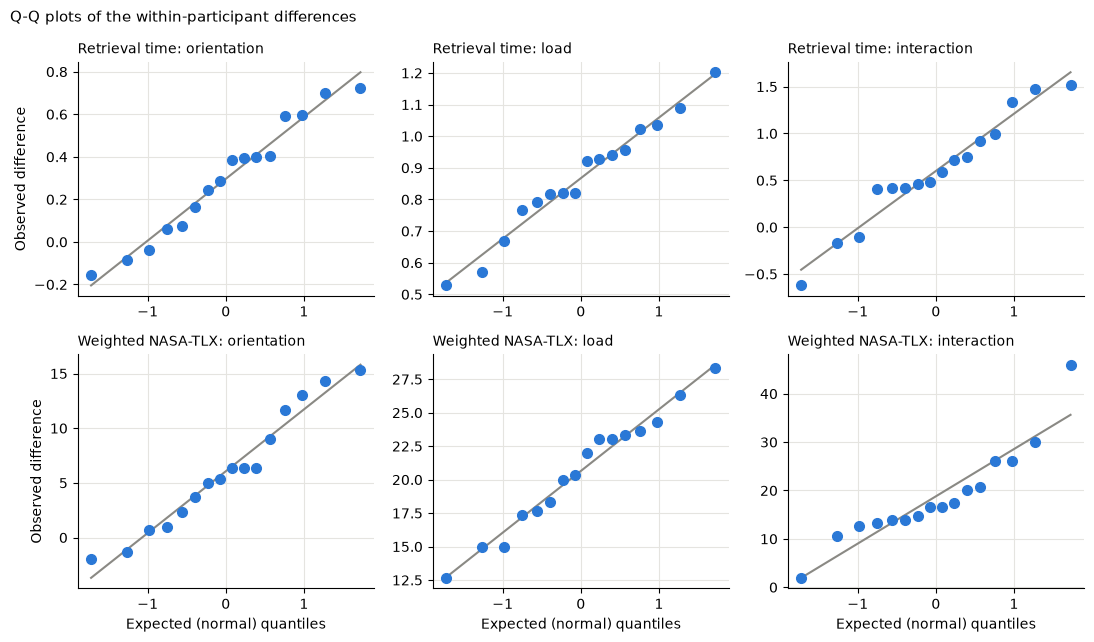

In [217]:
fig, axes = plt.subplots(2, 3, figsize=(11, 6.5))

for row, (outcome, label) in enumerate(NORMALITY_OUTCOMES.items()):
    for col, (name, values) in enumerate(diffs[outcome].items()):
        ax = axes[row, col]
        (expected, observed), (slope, intercept, _) = stats.probplot(values.dropna(), dist="norm")
        ax.plot(expected, slope * expected + intercept, color="#8a8984", linewidth=1.5)   # reference line
        ax.plot(expected, observed, "o", color="#2a78d6", markersize=7)                    # participants
        ax.set_title(f"{label}: {name}", fontsize=10, loc="left")
        ax.grid(color="#e5e4e0", linewidth=0.8)
        ax.spines[["top", "right"]].set_visible(False)
        if row == 1:
            ax.set_xlabel("Expected (normal) quantiles")
        if col == 0:
            ax.set_ylabel("Observed difference")

fig.suptitle("Q-Q plots of the within-participant differences", x=0.01, ha="left", fontsize=11)
fig.tight_layout()
plt.show()

### 2.2.4 Choosing the analysis route

Each outcome gets **one** route, used for all three of its effects (orientation, load, interaction) in 2.3:

- **Parametric → two-way repeated-measures ANOVA**, if all three Shapiro–Wilk tests give p ≥ 0.05 **and** the Q–Q plots show no clear departure from the line.
- **Non-parametric → aligned rank transform (ART) ANOVA**, otherwise.

The code first gives the route **suggested by the Shapiro–Wilk tests**. The team then confirms it against the Q–Q plots in 2.2.3. If a plot shows a clear problem the test missed, such as a strong curve or an extreme outlier, the route is overridden in the marked line, **with the reason written next to it**.

As paper section 4.7.3 requires, the routes are fixed **here, before any hypothesis test is run**, so the choice cannot be influenced by which route gives a significant result. If retrieval time fails because it is strongly skewed, the paper allows a log transformation, after which these checks are repeated.

The final routes are saved to `cleaned/analysis_routes.csv`, so the tests in 2.3 (run in R) use exactly the routes decided here.

In [ ]:
# Route suggested by the Shapiro-Wilk tests: parametric only if all three differences pass
suggested = (
    normality.groupby("outcome", sort=False)["normal (p >= .05)"].all()
    .map({True: "parametric", False: "non-parametric"})
)
print("Suggested by Shapiro-Wilk:")
print(suggested.to_string())

# Final routes, confirmed against the Q-Q plots in 2.2.3.
ROUTES = suggested.to_dict()
# Override only after looking at the Q-Q plots, and write the reason, e.g.:
# ROUTES["Weighted NASA-TLX"] = "non-parametric"   # reason: ...

# Save for the tests in 2.3, using the column names from condition_data
label_to_column = {label: column for column, label in NORMALITY_OUTCOMES.items()}
routes_table = pd.DataFrame({
    "outcome": [label_to_column[label] for label in ROUTES],
    "route": list(ROUTES.values()),
})
routes_table.to_csv(CLEANED_DIR / "analysis_routes.csv", index=False)
routes_table